# Weather Data: Seattle vs. St. Louis

## 1. Business understanding
Does it rain more in Seattle, Washington, than in St. Louis, Missouri? My parents think Seattle is too rainy. We use the data science methodology to investigate that belief using daily observations from January 1, 2018 through December 31, 2022.

We distinguish **amount** (mean daily precipitation) from **frequency** (percentage of observed days with at least 0.01 inches of precipitation). A city can have more wet days without receiving more water. Precipitation includes liquid-equivalent snow where reported; it is not exclusively rain.

This notebook covers data understanding, preparation, descriptive analysis, and communication. Graphs and summary statistics answer the question for the available observations; optional hypothesis tests are not required.

## 2. Data sources and study design

The project supplies [seattle_rain.csv](../data/seattle_rain.csv) and [stl_rain.csv](../data/stl_rain.csv). Station IDs and fields such as `STATION`, `DATE`, and `PRCP` follow NOAA GHCN-Daily / Climate Data Online conventions. The original download URLs, export settings, and quality flags were not supplied, so exact provenance and flag-based quality screening cannot be independently verified here. Relevant reference links:

- [NOAA Climate Data Online](https://www.ncei.noaa.gov/cdo-web/)
- [NOAA GHCN-Daily overview](https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily)
- [GHCN-Daily field and station documentation](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt)

**Units:** The project owner confirmed that the supplied precipitation values are in inches; no unit conversion is applied. GHCN's native archive units should not be assumed to be the units of a CDO export.

**Stations:** Seattle uses `US1WAKG0225` (SEATTLE 2.1 ESE). With the project owner's approval, St. Louis uses `USW00013994` (ST LOUIS LAMBERT INTERNATIONAL AIRPORT). The St. Louis file contains multiple stations; averaging or summing them would change the interpretation. One station per city avoids counting multiple observations as separate city-days, though the stations are not perfectly comparable or representative of entire cities.

We retain only dates with valid precipitation in both cities. We do not fill missing observations with zero or spread multi-day accumulations across unknown daily dates.

## 3. Load tools and locate project files
The next cell imports the analysis tools and identifies paths. Install the project requirements and select that Python environment before running all cells.

In [1]:
from pathlib import Path
import calendar

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working_directory = Path.cwd()
if (working_directory / 'data' / 'seattle_rain.csv').is_file():
    project_root = working_directory
elif (working_directory.parent / 'data' / 'seattle_rain.csv').is_file():
    project_root = working_directory.parent
else:
    raise FileNotFoundError('Run this notebook from the project root or code directory.')

data_directory = project_root / 'data'
report_directory = project_root / 'reports'
report_directory.mkdir(exist_ok=True)
start_date = pd.Timestamp('2018-01-01')
end_date = pd.Timestamp('2022-12-31')
calendar_dates = pd.date_range(start_date, end_date, name='date')
city_order = ['Seattle', 'St. Louis']
station_ids = {'Seattle': 'US1WAKG0225', 'St. Louis': 'USW00013994'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Study period: {start_date.date()} to {end_date.date()} ({len(calendar_dates):,} calendar days)')


Study period: 2018-01-01 to 2022-12-31 (1,826 calendar days)


The study calendar includes leap day in 2020. Paths are independent of a particular user's computer.

## 4. Inspect each raw dataset
Load the inputs without altering them. Show sample rows, data types, missing values, station counts, exact duplicates, and parsed date ranges. Blank CSV fields are read as missing values.

In [2]:
raw_data = {
    'Seattle': pd.read_csv(data_directory / 'seattle_rain.csv'),
    'St. Louis': pd.read_csv(data_directory / 'stl_rain.csv'),
}
date_formats = {'Seattle': '%m/%d/%y', 'St. Louis': '%Y-%m-%d'}

for city, frame in raw_data.items():
    display(Markdown(f'### {city}: {len(frame):,} raw rows'))
    display(frame.head())
    display(pd.DataFrame({'data_type': frame.dtypes.astype(str), 'missing_values': frame.isna().sum()}))
    parsed_dates = pd.to_datetime(frame['DATE'], format=date_formats[city], errors='raise')
    print(f'Dates: {parsed_dates.min().date()} to {parsed_dates.max().date()}')
    print(f'Exact duplicate rows: {frame.duplicated().sum():,}')
    display(frame.groupby(['STATION', 'NAME']).size().rename('rows').reset_index())


### Seattle: 1,658 raw rows

,STATION,NAME,DATE,DAPR,MDPR,PRCP,SNOW,SNWD,WESD,WESF
0,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1/1/18,NaN,NaN,0.00,NaN,NaN,NaN,NaN
1,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1/2/18,NaN,NaN,0.00,NaN,NaN,NaN,NaN
2,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1/3/18,NaN,NaN,0.00,NaN,NaN,NaN,NaN
3,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1/4/18,NaN,NaN,0.00,NaN,NaN,NaN,NaN
4,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1/5/18,NaN,NaN,0.25,NaN,NaN,NaN,NaN


,data_type,missing_values
STATION,str,0
NAME,str,0
DATE,str,0
DAPR,float64,1635
MDPR,float64,1635
PRCP,float64,22
SNOW,float64,1305
SNWD,float64,1592
WESD,float64,1643
WESF,float64,1630


Dates: 2018-01-01 to 2022-12-31
Exact duplicate rows: 0


,STATION,NAME,rows
0,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1658


### St. Louis: 54,574 raw rows

,STATION,NAME,DATE,DAPR,MDPR,PRCP,SNOW,SNWD
0,US1MOSS0027,"ST. CHARLES 2.3 NE, MO US",2017-01-01,NaN,NaN,0.00,0.0,NaN
1,US1MOSS0027,"ST. CHARLES 2.3 NE, MO US",2017-01-03,NaN,NaN,0.35,NaN,NaN
2,US1MOSS0027,"ST. CHARLES 2.3 NE, MO US",2017-01-04,NaN,NaN,0.03,NaN,NaN
3,US1MOSS0027,"ST. CHARLES 2.3 NE, MO US",2017-01-05,NaN,NaN,0.04,1.2,NaN
4,US1MOSS0027,"ST. CHARLES 2.3 NE, MO US",2017-01-06,NaN,NaN,0.00,0.0,1.0


,data_type,missing_values
STATION,str,0
NAME,str,0
DATE,str,0
DAPR,float64,53408
MDPR,float64,53411
PRCP,float64,1431
SNOW,float64,21407
SNWD,float64,41739


Dates: 2017-01-01 to 2022-12-31
Exact duplicate rows: 0


,STATION,NAME,rows
0,US1ILMD0010,"GRANITE CITY 1.4 ENE, IL US",2150
1,US1ILMD0012,"GRANITE CITY 2.3 NE, IL US",1954
2,US1ILMD0047,"GRANITE CITY 2.7 NE, IL US",218
3,US1ILMO0006,"COLUMBIA 0.4 S, IL US",162
4,US1ILSC0009,"BELLEVILLE 4.5 WNW, IL US",1399
5,US1ILSC0018,"FAIRMONT CITY 0.9 ENE, IL US",453
6,US1MOFSA189,"EDMUNDSON 0.7 NNW, MO US",1776
7,US1MOJF0018,"ARNOLD 0.5 E, MO US",2113
8,US1MOJF0025,"FENTON 4.1 S, MO US",1124
9,US1MOSL0004,"KIRKWOOD 1.6 S, MO US",1868


Seattle contains one station; St. Louis contains many stations and includes 2017. Dates initially have string/object types, and precipitation contains missing values. Multiple St. Louis rows on a date are different stations, not automatically duplicate observations. Fields such as snow depth and multi-day precipitation are outside this daily-precipitation comparison.

## 5. Convert, filter, deduplicate, and audit missingness
Parse dates with each file's explicit format and convert precipitation to numeric. Invalid dates, nonnumeric nonmissing precipitation, negative precipitation, and conflicting station-date duplicates raise errors instead of being silently discarded. Remove exact duplicates, choose the agreed station, restrict dates to 2018–2022, and keep only date and precipitation.

Reindex each selected station to the full calendar so absent rows are visible as well as blank precipitation values. Missing precipitation remains unknown: setting it to zero would incorrectly label unobserved days as dry. The audit records all filtering steps and coverage.

In [3]:
daily_by_city = {}
audit_rows = []

for city, raw_frame in raw_data.items():
    frame = raw_frame.copy()
    frame['date'] = pd.to_datetime(frame['DATE'], format=date_formats[city], errors='raise')
    frame['precipitation_inches'] = pd.to_numeric(frame['PRCP'], errors='raise')
    if frame['date'].isna().any():
        raise ValueError(f'{city}: missing dates require investigation.')
    if (frame['precipitation_inches'].dropna() < 0).any():
        raise ValueError(f'{city}: negative precipitation requires investigation.')

    exact_duplicates = int(frame.duplicated().sum())
    frame = frame.drop_duplicates()
    station_rows = frame.loc[frame['STATION'].eq(station_ids[city])].copy()
    if station_rows.empty:
        raise ValueError(f'{city}: expected station is absent.')
    selected = station_rows.loc[station_rows['date'].between(start_date, end_date)].copy()
    if selected['date'].duplicated().any():
        raise ValueError(f'{city}: conflicting station-date duplicates require investigation.')

    daily = selected[['date', 'precipitation_inches']].set_index('date').reindex(calendar_dates)
    valid_days = int(daily['precipitation_inches'].notna().sum())
    audit_rows.append({
        'city': city,
        'raw_rows': len(raw_frame),
        'exact_duplicates_removed': exact_duplicates,
        'other_station_rows_removed': len(frame) - len(station_rows),
        'outside_period_rows_removed': len(station_rows) - len(selected),
        'selected_rows': len(selected),
        'missing_calendar_dates': len(calendar_dates) - len(selected),
        'missing_precipitation_in_existing_rows': int(selected['precipitation_inches'].isna().sum()),
        'valid_days': valid_days,
        'coverage_percent': 100 * valid_days / len(calendar_dates),
    })
    daily_by_city[city] = daily

coverage_audit = pd.DataFrame(audit_rows)
coverage_audit.to_csv(report_directory / 'coverage_audit.csv', index=False)
display(coverage_audit.round(2))


,city,raw_rows,exact_duplicates_removed,other_station_rows_removed,outside_period_rows_removed,selected_rows,missing_calendar_dates,missing_precipitation_in_existing_rows,valid_days,coverage_percent
0,Seattle,1658,0,0,0,1658,168,22,1636,89.59
1,St. Louis,54574,0,52383,365,1826,0,0,1826,100.00


The audit distinguishes dates absent from the file from rows present without precipitation. Coverage is based on all calendar days, not just rows in the export. Removing other stations and out-of-period observations is intentional filtering, not an assertion that those records are erroneous.

## 6. Join on common valid dates
Join the two daily series by date, preserving the full calendar initially. Then remove dates where either city lacks precipitation. This gives both cities the same dates and denominators, although it cannot remove bias if missing observations are related to weather. Summarize retained dates by year and month to expose uneven coverage.

In [4]:
all_dates = daily_by_city['Seattle'].rename(columns={'precipitation_inches': 'Seattle'}).join(
    daily_by_city['St. Louis'].rename(columns={'precipitation_inches': 'St. Louis'}),
    how='outer', validate='one_to_one',
)
paired_daily = all_dates.dropna(subset=city_order).copy()
if paired_daily.empty:
    raise ValueError('There are no common valid dates to compare.')

coverage_calendar = pd.DataFrame({'date': calendar_dates})
coverage_calendar['year'] = coverage_calendar['date'].dt.year
coverage_calendar['month'] = coverage_calendar['date'].dt.month
coverage_calendar['paired_day'] = coverage_calendar['date'].isin(paired_daily.index)
monthly_coverage = coverage_calendar.groupby(['year', 'month'], as_index=False).agg(
    calendar_days=('date', 'size'), paired_days=('paired_day', 'sum'),
)
monthly_coverage['coverage_percent'] = 100 * monthly_coverage['paired_days'] / monthly_coverage['calendar_days']
monthly_coverage.to_csv(report_directory / 'monthly_coverage.csv', index=False)
display(monthly_coverage.pivot(index='year', columns='month', values='paired_days'))
display(Markdown(
    f'**Matched sample:** {len(paired_daily):,} of {len(calendar_dates):,} days '
    f'({100 * len(paired_daily) / len(calendar_dates):.1f}%). '
    f'Excluded {len(calendar_dates) - len(paired_daily):,} calendar dates with missing precipitation in at least one city.'
))


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2018,8,0,20,30,31,30,31,31,29,31,20,31
2019,26,22,31,27,31,24,25,24,30,31,22,31
2020,28,18,31,30,31,30,31,31,20,31,30,31
2021,31,24,18,25,31,30,30,12,30,31,30,31
2022,31,28,21,30,31,30,31,31,30,31,30,31


**Matched sample:** 1,636 of 1,826 days (89.6%). Excluded 190 calendar dates with missing precipitation in at least one city.

The table shows paired days in each year-month, not complete month lengths. Results apply to these shared observations; we must not call their precipitation sums complete annual or monthly totals.

## 7. Reshape to tidy data and derive useful variables
Convert the joined table to long format: one row per city per matched date. Use lowercase snake_case columns, derive calendar year/month, and mark a wet day as precipitation of at least 0.01 inches. The raw files do not distinguish trace amounts, so this is measurable precipitation, not every possible trace event. Export the clean dataset and check its structure.

In [5]:
weather_clean = paired_daily.reset_index().melt(
    id_vars='date', value_vars=city_order,
    var_name='city', value_name='precipitation_inches',
)
weather_clean['year'] = weather_clean['date'].dt.year
weather_clean['month'] = weather_clean['date'].dt.month
weather_clean['is_wet_day'] = weather_clean['precipitation_inches'].ge(0.01)
weather_clean = weather_clean.sort_values(['date', 'city']).reset_index(drop=True)

assert len(weather_clean) == 2 * len(paired_daily)
assert not weather_clean.isna().any().any()
assert not weather_clean.duplicated(['date', 'city']).any()
assert weather_clean.groupby('date')['city'].nunique().eq(2).all()
assert weather_clean['date'].between(start_date, end_date).all()
assert weather_clean['precipitation_inches'].ge(0).all()
assert all(column == column.lower() and ' ' not in column for column in weather_clean.columns)
clean_path = data_directory / 'weather_clean.csv'
weather_clean.to_csv(clean_path, index=False, date_format='%Y-%m-%d')
display(weather_clean.head(10))
print(f'Saved {len(weather_clean):,} rows to {clean_path.name}')


,date,city,precipitation_inches,year,month,is_wet_day
0,2018-01-01,Seattle,0.00,2018,1,False
1,2018-01-01,St. Louis,0.00,2018,1,False
2,2018-01-02,Seattle,0.00,2018,1,False
3,2018-01-02,St. Louis,0.00,2018,1,False
4,2018-01-03,Seattle,0.00,2018,1,False
5,2018-01-03,St. Louis,0.00,2018,1,False
6,2018-01-04,Seattle,0.00,2018,1,False
7,2018-01-04,St. Louis,0.00,2018,1,False
8,2018-01-05,Seattle,0.25,2018,1,True
9,2018-01-05,St. Louis,0.00,2018,1,False


Saved 3,272 rows to weather_clean.csv


The exported columns are `date`, `city`, `precipitation_inches`, `year`, `month`, and `is_wet_day`. Each date has exactly two records, one per city, and every precipitation value is observed rather than imputed. Derived fields make seasonal and frequency comparisons straightforward.

## 8. Summarize precipitation amount and frequency
Compute mean daily precipitation across all matched days (including dry days), the percentage of matched days that are wet, and mean precipitation on wet days only. Also summarize each calendar month across the five years. The monthly means are daily amounts, not monthly totals; months with more observed days receive more weight.

In [6]:
summary = weather_clean.groupby('city').agg(
    observed_days=('date', 'size'),
    observed_precipitation_sum_inches=('precipitation_inches', 'sum'),
    mean_daily_precipitation_inches=('precipitation_inches', 'mean'),
    wet_days=('is_wet_day', 'sum'),
    wet_day_fraction=('is_wet_day', 'mean'),
).reindex(city_order)
summary['wet_day_percent'] = 100 * summary.pop('wet_day_fraction')
summary['mean_wet_day_precipitation_inches'] = (
    weather_clean.loc[weather_clean['is_wet_day']].groupby('city')['precipitation_inches'].mean()
)
monthly_summary = weather_clean.groupby(['month', 'city'], as_index=False).agg(
    observed_days=('date', 'size'),
    mean_daily_precipitation_inches=('precipitation_inches', 'mean'),
    wet_day_fraction=('is_wet_day', 'mean'),
)
monthly_summary['wet_day_percent'] = 100 * monthly_summary.pop('wet_day_fraction')
summary.to_csv(report_directory / 'city_summary.csv', index_label='city')
monthly_summary.to_csv(report_directory / 'monthly_summary.csv', index=False)
display(summary.round(4))
display(monthly_summary.round(4))
assert summary['observed_days'].nunique() == 1
assert summary['wet_day_percent'].between(0, 100).all()
assert monthly_summary.groupby('month')['observed_days'].nunique().eq(1).all()


,observed_days,observed_precipitation_sum_inches,mean_daily_precipitation_inches,wet_days,wet_day_percent,mean_wet_day_precipitation_inches
city,,,,,,
Seattle,1636,182.99,0.1119,841,51.4059,0.2176
St. Louis,1636,219.17,0.1340,533,32.5795,0.4112


,month,city,observed_days,mean_daily_precipitation_inches,wet_day_percent
0,1,Seattle,124,0.2286,70.9677
1,1,St. Louis,124,0.1197,31.4516
2,2,Seattle,92,0.1929,76.0870
3,2,St. Louis,92,0.1082,40.2174
4,3,Seattle,121,0.0899,42.9752
5,3,St. Louis,121,0.1933,38.0165
6,4,Seattle,142,0.0994,58.4507
7,4,St. Louis,142,0.1511,42.2535
8,5,Seattle,155,0.0692,46.4516
9,5,St. Louis,155,0.1748,43.2258


The amount and frequency columns answer different versions of 'rainier.' The observed precipitation sums use equal matched-date coverage, but they are not full-period totals because some dates are missing. Mean wet-day precipitation helps explain how less frequent but heavier events can produce a larger average daily amount.

## 9. Compare the cities visually
Use two clearly labeled panels rather than mixing inches and percentages on one axis. All values come directly from the summary table and both cities use the same dates.

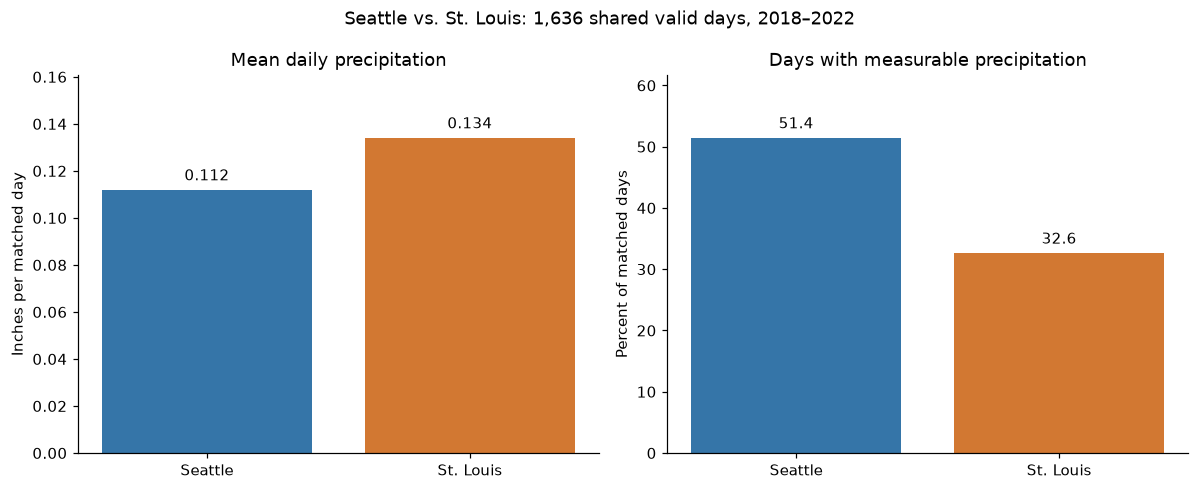

**Reading the graph:** St. Louis has the higher observed mean daily amount; Seattle has the higher observed wet-day percentage. These metrics need not identify the same city.

In [7]:
colors = ['#3575a8', '#d27832']
figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
panels = [
    ('mean_daily_precipitation_inches', 'Mean daily precipitation', 'Inches per matched day', '.3f'),
    ('wet_day_percent', 'Days with measurable precipitation', 'Percent of matched days', '.1f'),
]
for axis, (column, title, ylabel, number_format) in zip(axes, panels):
    bars = axis.bar(city_order, summary[column], color=colors)
    axis.set(title=title, ylabel=ylabel)
    axis.set_ylim(0, summary[column].max() * 1.2)
    axis.bar_label(bars, labels=[format(value, number_format) for value in summary[column]], padding=4)
figure.suptitle(f'Seattle vs. St. Louis: {len(paired_daily):,} shared valid days, 2018–2022')
figure.tight_layout()
figure.savefig(report_directory / 'overall_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

amount_city = summary['mean_daily_precipitation_inches'].idxmax()
frequency_city = summary['wet_day_percent'].idxmax()
display(Markdown(
    f'**Reading the graph:** {amount_city} has the higher observed mean daily amount; '
    f'{frequency_city} has the higher observed wet-day percentage. '
    'These metrics need not identify the same city.'
))


The graph compares overall amount with frequency. It summarizes the sampled days only and does not establish a long-run climate difference or statistical significance.

## 10. Examine seasonality
Plot average daily precipitation and wet-day percentage by calendar month. Grouping the same calendar months across years makes seasonal patterns visible; this is different from comparing full monthly totals. Refer to the year-month coverage table when interpreting the lines.

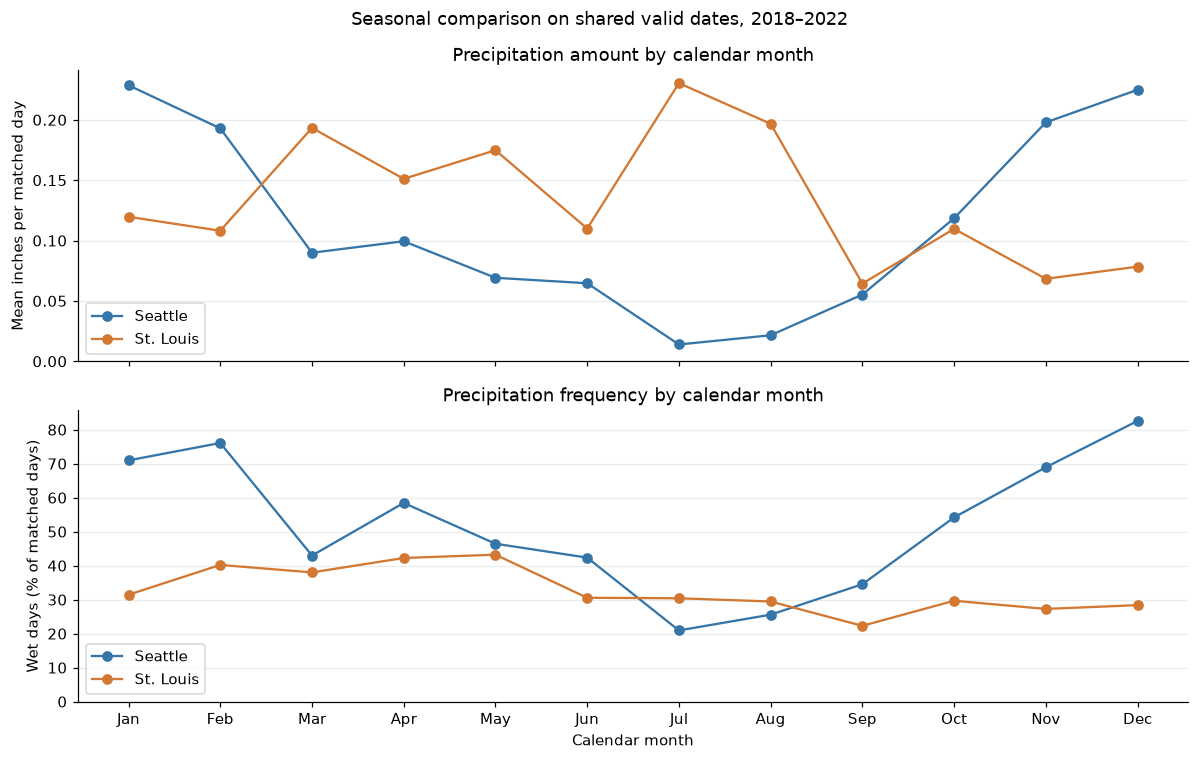

**Seasonal interpretation:** Seattle has the higher mean daily precipitation in Jan, Feb, Oct, Nov, Dec, and the higher wet-day percentage in Jan, Feb, Mar, Apr, May, Jun, Sep, Oct, Nov, Dec. These are descriptive comparisons of the available observations, not significance tests.

In [8]:
figure, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for city, color in zip(city_order, colors):
    city_months = monthly_summary.loc[monthly_summary['city'].eq(city)].set_index('month').reindex(range(1, 13))
    axes[0].plot(city_months.index, city_months['mean_daily_precipitation_inches'], marker='o', label=city, color=color)
    axes[1].plot(city_months.index, city_months['wet_day_percent'], marker='o', label=city, color=color)
axes[0].set(ylabel='Mean inches per matched day', title='Precipitation amount by calendar month')
axes[1].set(ylabel='Wet days (% of matched days)', xlabel='Calendar month', title='Precipitation frequency by calendar month')
axes[1].set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
for axis in axes:
    axis.set_ylim(bottom=0)
    axis.grid(axis='y', alpha=0.25)
    axis.legend()
figure.suptitle('Seasonal comparison on shared valid dates, 2018–2022')
figure.tight_layout()
figure.savefig(report_directory / 'monthly_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

amount_by_month = monthly_summary.pivot(index='month', columns='city', values='mean_daily_precipitation_inches')
frequency_by_month = monthly_summary.pivot(index='month', columns='city', values='wet_day_percent')
seattle_amount_months = [calendar.month_abbr[month] for month in amount_by_month.index[amount_by_month['Seattle'] > amount_by_month['St. Louis']]]
seattle_frequency_months = [calendar.month_abbr[month] for month in frequency_by_month.index[frequency_by_month['Seattle'] > frequency_by_month['St. Louis']]]
display(Markdown(
    '**Seasonal interpretation:** Seattle has the higher mean daily precipitation in '
    + (', '.join(seattle_amount_months) or 'none of the calendar months')
    + ', and the higher wet-day percentage in '
    + (', '.join(seattle_frequency_months) or 'none of the calendar months')
    + '. These are descriptive comparisons of the available observations, not significance tests.'
))


The seasonal graph and generated interpretation show when Seattle exceeds St. Louis for each metric. Looking only at the overall average would hide these calendar-month differences. Uneven missingness can still affect these comparisons.

## 11. Conclusions and communication
Generate the numerical conclusion directly from the summary table so it remains consistent with the exported tables and graphs when the notebook is rerun.

In [9]:
seattle = summary.loc['Seattle']
st_louis = summary.loc['St. Louis']
amount_difference = seattle['mean_daily_precipitation_inches'] - st_louis['mean_daily_precipitation_inches']
frequency_difference = seattle['wet_day_percent'] - st_louis['wet_day_percent']
amount_answer = 'more' if amount_difference > 0 else 'less' if amount_difference < 0 else 'the same amount of'
frequency_answer = 'more often' if frequency_difference > 0 else 'less often' if frequency_difference < 0 else 'equally often'
display(Markdown(
    f'On **{len(paired_daily):,} matched dates** in 2018–2022, Seattle received **{amount_answer} precipitation** '
    f'by mean daily amount and had measurable precipitation **{frequency_answer}** than St. Louis.\n\n'
    f'- **Amount:** Seattle averaged **{seattle["mean_daily_precipitation_inches"]:.3f} inches/day**, '
    f'compared with **{st_louis["mean_daily_precipitation_inches"]:.3f} inches/day** in St. Louis '
    f'(Seattle minus St. Louis: {amount_difference:+.3f} inches/day).\n'
    f'- **Frequency:** Seattle had measurable precipitation on **{seattle["wet_day_percent"]:.1f}%** of matched days, '
    f'compared with **{st_louis["wet_day_percent"]:.1f}%** in St. Louis '
    f'(difference: {frequency_difference:+.1f} percentage points).\n'
    f'- **Wet-day amount:** Seattle averaged **{seattle["mean_wet_day_precipitation_inches"]:.3f} inches** on wet days; '
    f'St. Louis averaged **{st_louis["mean_wet_day_precipitation_inches"]:.3f} inches**.\n\n'
    'Therefore, the answer to whether Seattle is rainier depends on whether we mean precipitation amount or frequency. '
    'These observations inform the family discussion, but do not determine whether either city is too rainy for a particular person.'
))


On **1,636 matched dates** in 2018–2022, Seattle received **less precipitation** by mean daily amount and had measurable precipitation **more often** than St. Louis.

- **Amount:** Seattle averaged **0.112 inches/day**, compared with **0.134 inches/day** in St. Louis (Seattle minus St. Louis: -0.022 inches/day).
- **Frequency:** Seattle had measurable precipitation on **51.4%** of matched days, compared with **32.6%** in St. Louis (difference: +18.8 percentage points).
- **Wet-day amount:** Seattle averaged **0.218 inches** on wet days; St. Louis averaged **0.411 inches**.

Therefore, the answer to whether Seattle is rainier depends on whether we mean precipitation amount or frequency. These observations inform the family discussion, but do not determine whether either city is too rainy for a particular person.

### Limitations and next steps

- **Missingness:** Matching dates avoids unequal sample sizes but does not make missing data random. Unobserved days cannot be assumed dry, and sums of retained observations are not full-year totals.
- **Station representativeness:** One Seattle neighborhood station and one St. Louis airport may differ in measurement practices, reporting times, and local weather. Same labeled dates may not cover exactly the same observation windows. Results are about these stations, not every location in either city.
- **Measurement and provenance:** Units were confirmed by the project owner. Original export links/settings and quality flags were unavailable. Trace precipitation cannot be distinguished, and multi-day accumulations were not substituted for missing daily values. Precipitation can include snow water equivalent.
- **Scope of inference:** Five consecutive years are not established to be a random sample of climate years. Daily observations are seasonally structured and may be serially correlated. We report descriptive results only and do not claim statistical significance or a long-term climate conclusion.
- **Optional hypothesis testing:** Testing monthly means would require a justified sampling model and attention to dependence, the small number of years, and 12 simultaneous comparisons. No hypothesis tests are performed here.
- **Improvements:** Obtain original export metadata and quality flags, compare longer and more complete station records, and assess sensitivity to station selection and missing-data patterns.

### Reproducible deliverables

- Clean long-format observations: [weather_clean.csv](../data/weather_clean.csv)
- Coverage reports: [coverage_audit.csv](../reports/coverage_audit.csv) and [monthly_coverage.csv](../reports/monthly_coverage.csv)
- Summary tables: [city_summary.csv](../reports/city_summary.csv) and [monthly_summary.csv](../reports/monthly_summary.csv)
- Figures: [overall_comparison.png](../reports/overall_comparison.png) and [monthly_comparison.png](../reports/monthly_comparison.png)

Run all cells from top to bottom to regenerate every table, figure, and conclusion from the unmodified raw inputs.